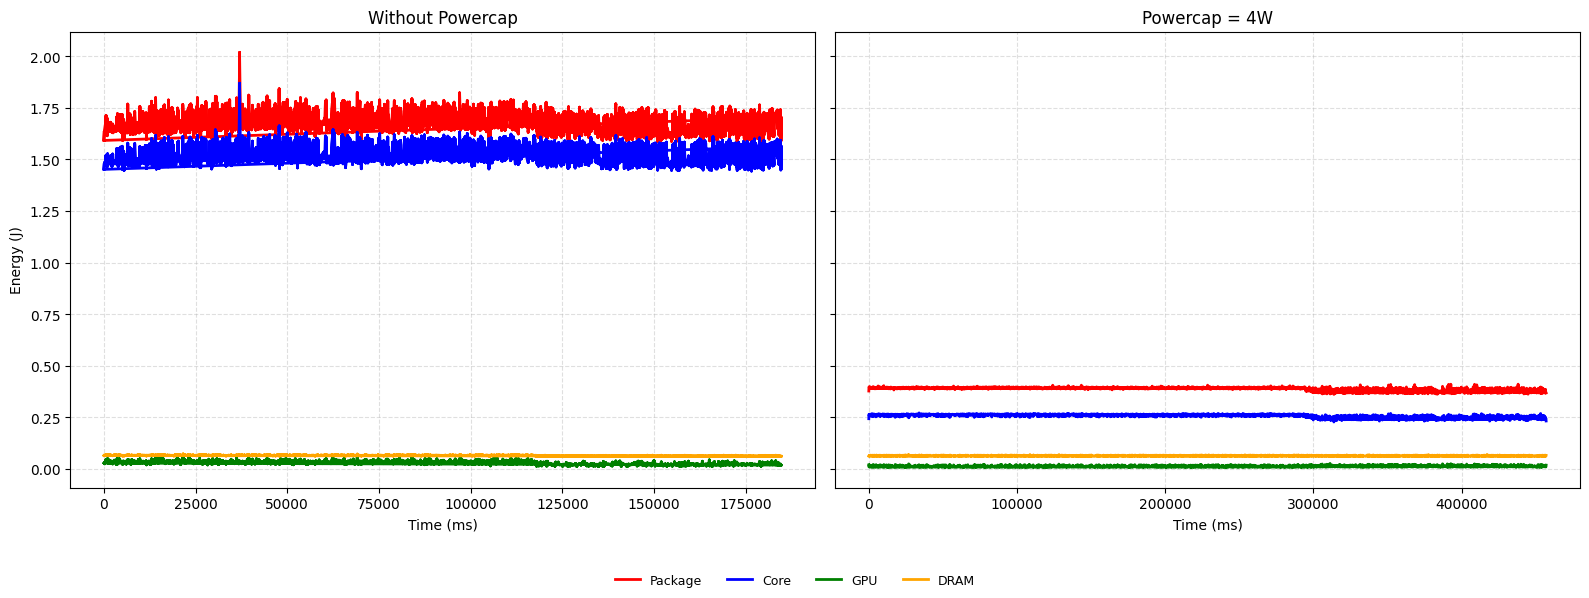

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df_energy = pd.read_csv("../csv_files/measurements_ot.csv")

# Energy columns and colors
energy_cols = ['Package', 'Core', 'GPU', 'DRAM']
colors = ['red', 'blue', 'green', 'orange']

# Powercaps
powercaps = sorted(df_energy['Powercap'].unique())

# Create two subplots (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16,6), sharey=True)

titles = {
    -1: "Without Powercap",
    4: "Powercap = 4W"
}

for ax, pc in zip(axes, powercaps):
    subset = df_energy[df_energy['Powercap'] == pc]
    
    for i, col in enumerate(energy_cols):
        ax.plot(
            subset['Timestamp'],
            subset[col],
            color=colors[i],
            linewidth=2,
            label=col
        )
    
    ax.set_title(titles[pc])
    ax.set_xlabel("Time (ms)")
    ax.grid(True, linestyle='--', alpha=0.4)

axes[0].set_ylabel("Energy (J)")

# Legend below the plots with 4 columns
fig.legend(
    energy_cols,
    loc='lower center',
    ncol=4,
    title="",
    fontsize=9,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])  # Leave space at the bottom for legend
plt.show()


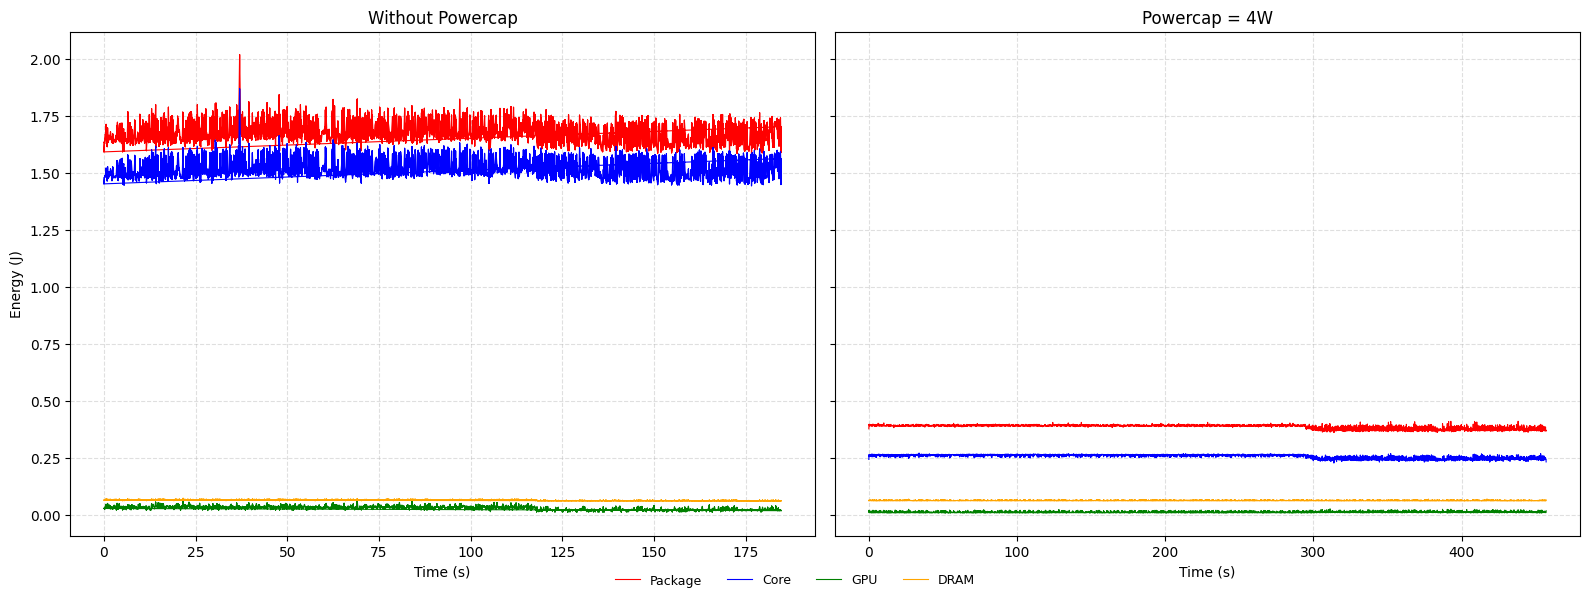

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df_energy = pd.read_csv("../csv_files/measurements_ot.csv")

# Energy columns and colors
energy_cols = ['Package', 'Core', 'GPU', 'DRAM']
colors = ['red', 'blue', 'green', 'orange']

# Powercaps
powercaps = sorted(df_energy['Powercap'].unique())

# Create two subplots (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16,6), sharey=True)

titles = {
    -1: "Without Powercap",
    4: "Powercap = 4W"
}

for ax, pc in zip(axes, powercaps):
    subset = df_energy[df_energy['Powercap'] == pc]
    
    for i, col in enumerate(energy_cols):
        ax.plot(
            subset['Timestamp'] / 1000,  # Convert to seconds
            subset[col],
            color=colors[i],
            linewidth=0.8,  # thin line
            label=col
        )
    
    ax.set_title(titles.get(pc, f"Powercap = {pc}W"))
    ax.set_xlabel("Time (s)")
    ax.grid(True, linestyle='--', alpha=0.4)

axes[0].set_ylabel("Energy (J)")

# Legend below the plots with 4 columns
fig.legend(
    energy_cols,
    loc='lower center',
    ncol=4,
    title="",
    fontsize=9,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 1])  # Leave space at the bottom for legend
plt.show()


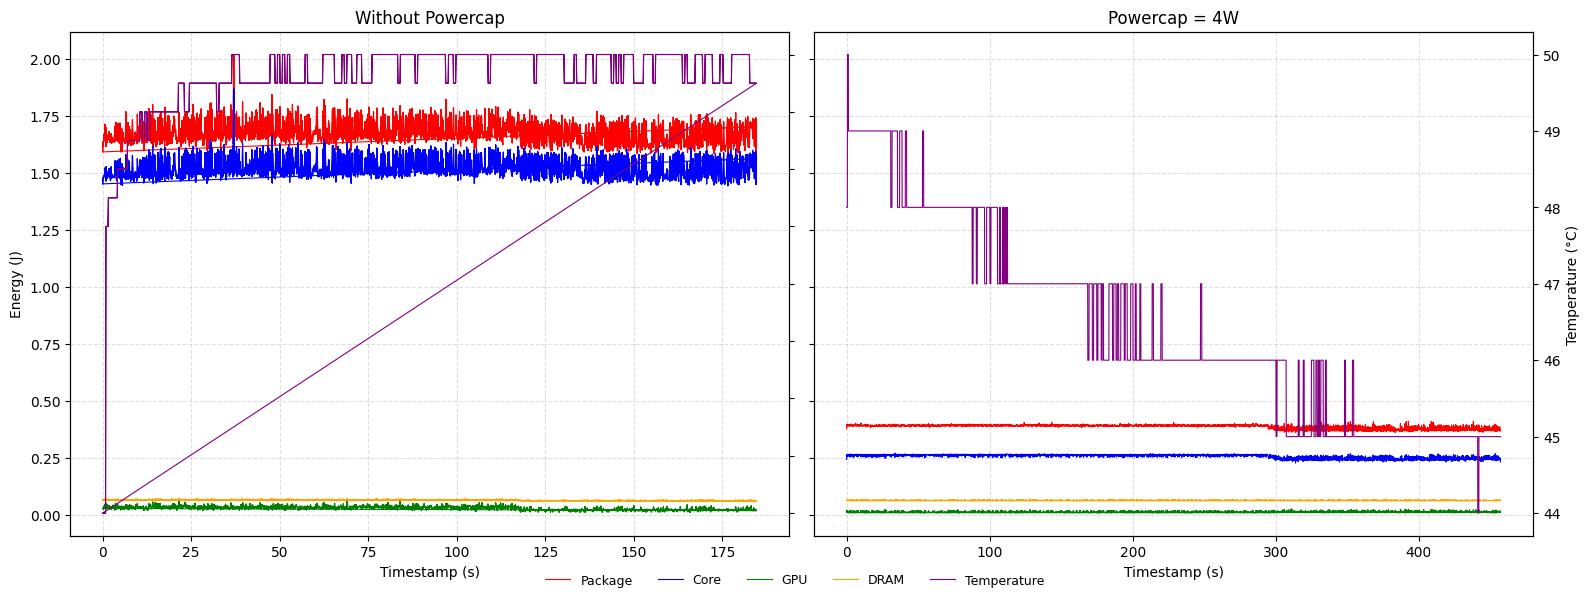

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df_energy = pd.read_csv("../csv_files/measurements_ot.csv")

# Energy columns and colors
energy_cols = ['Package', 'Core', 'GPU', 'DRAM']
colors = ['red', 'blue', 'green', 'orange']

# Powercaps
powercaps = sorted(df_energy['Powercap'].unique())

# Create two subplots (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16,6), sharey=True)

titles = {
    -1: "Without Powercap",
    4: "Powercap = 4W"
}

# Store handles for the legend
energy_handles = []
temperature_handle = None

for idx, (ax, pc) in enumerate(zip(axes, powercaps)):
    subset = df_energy[df_energy['Powercap'] == pc]
    
    # Plot energy lineplots (thin)
    for i, col in enumerate(energy_cols):
        line, = ax.plot(
            subset['Timestamp'] / 1000,
            subset[col],
            color=colors[i],
            linewidth=0.8,
            label=col
        )
        if idx == 0:
            energy_handles.append(line)
    
    # Temperature as thin line on secondary y-axis
    ax2 = ax.twinx()
    temp_line, = ax2.plot(
        subset['Timestamp'] / 1000,
        subset['Temperature'],
        color='purple',
        linewidth=0.8,
        label='Temperature'
    )
    if idx == 1:
        temperature_handle = temp_line
    
    # Temperature y-axis label only on rightmost plot, in black
    if idx == 1:
        ax2.set_ylabel("Temperature (°C)", color='black')
        ax2.tick_params(axis='y', labelcolor='black')
    else:
        ax2.set_yticklabels([])  # hide y-ticks for left plot
    
    ax.set_title(titles.get(pc, f"Powercap = {pc}W"))
    ax.set_xlabel("Timestamp (s)")
    ax.grid(True, linestyle='--', alpha=0.4)

axes[0].set_ylabel("Energy (J)")

# Combine legend (energy + temperature)
fig.legend(
    handles=energy_handles + [temperature_handle],
    labels=energy_cols + ['Temperature'],
    loc='lower center',
    ncol=5,
    fontsize=9,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 1])
#plt.savefig("overtime.pdf", format='pdf', bbox_inches='tight')
plt.show()
